# Week 3 — let the image notes talk

The CNN writes short notes about parts of a hyperspectral patch. The transformer lets those notes compare information. A classifier then chooses Health, Other or Rust. We separately build simulated acreage analytics. This is a small educational hybrid, not a large pretrained ViT.

## 1. Open our saved experiment
In VS Code, select the project `.venv` kernel. The small model and reports are committed. The notebook does not train again unless you enable the optional switch at the end.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import torch
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
torch.set_num_threads(2)
current = json.loads((ROOT / "reports/week3/metrics.json").read_text())
previous = json.loads((ROOT / "reports/week2/metrics.json").read_text())
print(current["model"], "parameters:", current["parameters"])
print("Same manifest:", current["manifest_sha256"] == previous["manifest_sha256"])

Compact CNN + vision transformer parameters: 24407
Same manifest: True


## 2. Follow the notes through the model
Our input has 16 PCA pages, each 16×16 pixels. PCA pages are mixtures of original bands, not named wavelengths. Two 3D convolutions learn local patterns. We fold depth features into channels and make 16 spatial tokens with 32 numbers each. Position embeddings tell the model where each token belongs. Four attention heads compare these tokens; mean pooling and a linear classifier produce three scores.

In [2]:
from terraspectra.model import load_model
model, checkpoint = load_model(ROOT / "models/week3/hybrid_vit.pt")
# A zero-filled input illustrates shapes only; it is not a real leaf prediction.
example = torch.zeros(1, 1, 16, 16, 16)
with torch.inference_mode():
    features = model.features(example)
    tokens = model.tokens(features.flatten(1, 2)).flatten(2).transpose(1, 2)
    attended = model.attention(tokens + model.position)
    logits = model(example)
print("CNN features:", tuple(features.shape))
print("Tokens:", tuple(tokens.shape))
print("Attention output:", tuple(attended.shape))
print("Class logits:", tuple(logits.shape))

CNN features: (1, 12, 8, 8, 8)
Tokens: (1, 16, 32)
Attention output: (1, 16, 32)
Class logits: (1, 3)


Attention compares spatial tokens containing learned spectral information. It does not directly compare all original wavelengths or measure chemicals. This is why our report says “CNN + vision transformer” and does not claim chemical detection.

## 3. Compare fairly, and read more than one number
All models use the same 120 development-validation patches. Accuracy counts correct answers; macro F1 gives all classes equal weight. This split also chooses the checkpoint. It is not an independent test set.

Logistic: accuracy 0.642, macro F1 0.645
Week 2 CNN: accuracy 0.658, macro F1 0.635
Week 3 hybrid: accuracy 0.708, macro F1 0.707


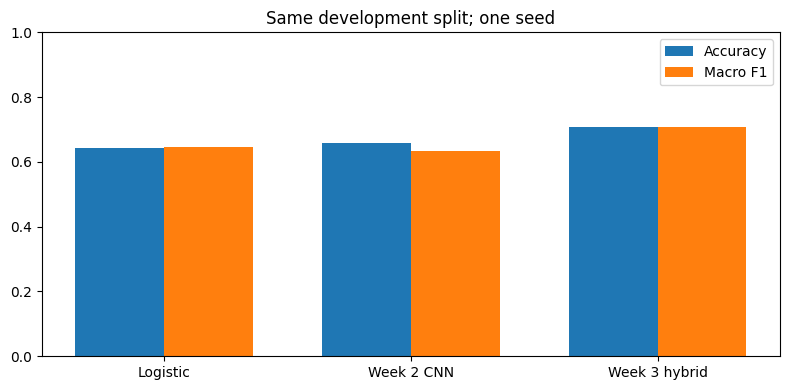

In [3]:
names = ["Logistic", "Week 2 CNN", "Week 3 hybrid"]
scores = [current["baseline"], previous["cnn"], current["transformer"]]
for name, score in zip(names, scores):
    print(f"{name}: accuracy {score['accuracy']:.3f}, macro F1 {score['macro_f1']:.3f}")
x = np.arange(3)
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(x-0.18, [s["accuracy"] for s in scores], width=0.36, label="Accuracy")
ax.bar(x+0.18, [s["macro_f1"] for s in scores], width=0.36, label="Macro F1")
ax.set(xticks=x, xticklabels=names, ylim=(0,1), title="Same development split; one seed")
ax.legend(); fig.tight_layout(); plt.show()

## 4. Where did it make mistakes?
Rows in the confusion matrix mean the actual class; columns mean the predicted class. The diagonal shows correct answers. We keep mistakes visible, because a useful model needs more than a good-looking overall number.

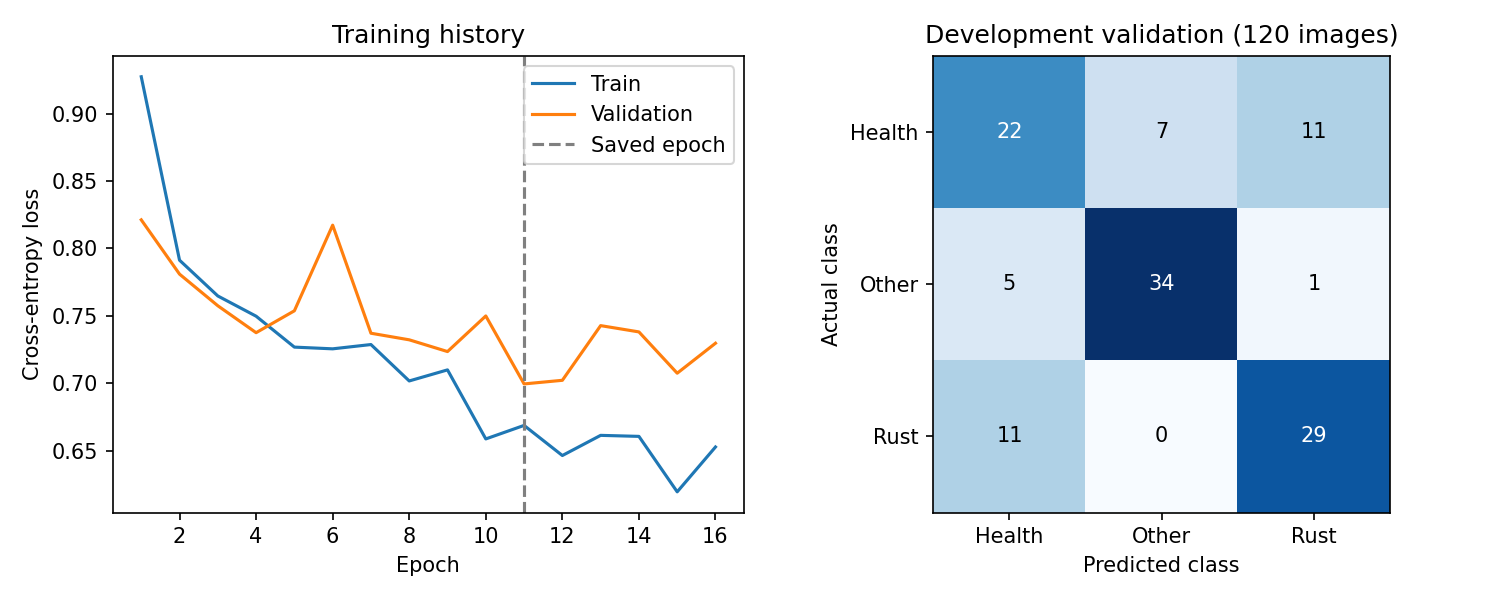

Health recall: 0.55
Other recall: 0.85
Rust recall: 0.725
Seconds: 19.1 saved epoch: 11


In [4]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "reports/week3/training_results.png")))
for name in current["classes"]:
    print(name, "recall:", current["transformer"]["per_class"][name]["recall"])
print("Seconds:", round(current["elapsed_seconds"], 1), "saved epoch:", current["best_epoch"])

One seed cannot prove statistical significance. The token projection and classification head also changed, so this is not an attention-only ablation. Runtime varies with machine conditions; do not interpret the historical Week 2 timing as a controlled speed comparison.

## 5. Optional real TIFF prediction
The saved model can process a local TIFF with the same numeric PCA recipe. This cell skips cleanly if you have not prepared the raw dataset. Softmax scores are not calibrated probabilities.

In [5]:
from terraspectra.predict import predict
image_path = ROOT / "data/raw/train/Health/hyper (1).tif"
if image_path.exists():
    print(json.dumps(predict(image_path, ROOT / "models/week3"), indent=2))
else:
    print("Raw TIFF absent. Run Week 1 preparation to use this optional example.")

Python(46752) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


{
  "file": "hyper (1).tif",
  "predicted_class": "Health",
  "scores": {
    "Health": 0.4834069311618805,
    "Other": 0.47769057750701904,
    "Rust": 0.038902394473552704
  },
  "note": "Uncalibrated patch-class scores; no pixel mask or farm coordinates."
}


## 6. Simulated acreage: add up the selected squares
The map cells belong to an invented farm, independent of these predictions. We approximate rectangular area on a spherical Earth. This is suitable for a demonstration, not a land survey. Moving the dashboard score slider changes which cells are selected.

Total synthetic acres: 142.81


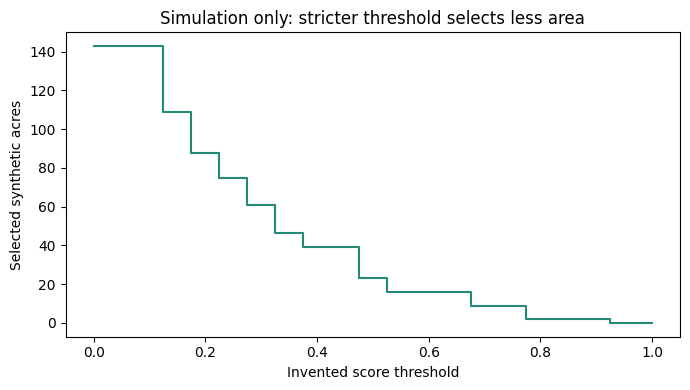

In [6]:
grid = json.loads((ROOT / "frontend/public/mock-heatmap.json").read_text())
def acres(bounds):
    west, south, east, north = np.radians(bounds)
    return 6371008.8**2 * (east-west) * (np.sin(north)-np.sin(south)) / 4046.8564224
thresholds = np.linspace(0,1,21)
areas = [sum(acres(c["bounds"]) for c in grid["cells"] if c["score"] >= t) for t in thresholds]
print("Total synthetic acres:", round(areas[0],2))
fig, ax = plt.subplots(figsize=(7,4))
ax.step(thresholds, areas, where="mid", color="#238b75")
ax.set(xlabel="Invented score threshold", ylabel="Selected synthetic acres", title="Simulation only: stricter threshold selects less area")
fig.tight_layout(); plt.show()

The panel also shows low/medium/high cell counts and area. That distribution describes the whole grid; the selected-acre figure follows the slider. Hiding a layer changes visibility, not which records meet the threshold. None of these values are disease acreage.

## 7. Chemical anomalies are not available
Our labels only say Health, Other and Rust. We cannot turn Other into nitrogen deficiency, chlorophyll concentration or a specific chemical diagnosis. The panel states this limitation instead of making up results. Likewise, no three-week forecast or actual farm localization is established.

## 8. Optional training
Leave this off to use the saved result. Enabling it runs one bounded CPU experiment and overwrites only Week 3 outputs. Rerun earlier cells after training to load the new reports.

In [7]:
RUN_TRAINING = False
if RUN_TRAINING:
    from terraspectra.train import train
    train(architecture="hybrid_vit")
else:
    print("Saved model used; no retraining.")

Saved model used; no retraining.


## Explain it to your mentor
“I added a small attention layer after CNN feature extraction. I compared it against earlier models on the same development split and retained the saved weights and predictions. I added interactive simulated acreage analytics, while clearly separating those mock values from real patch classification.”

See [the guide](../docs/WEEK_3_GUIDE.md) and [primary-source research](../docs/WEEK_3_RESEARCH.md).